Support Vector Machine - AI Training Software
Copyright (C) 2024 AI Institute, University of South Carolina

Authors:    Homayoun Valafar
            Andrew Smith
            Christopher Lee
            Alireza Bagheri
            Musa Azim
         

This program is free software: you can redistribute it and/or modify
it under the terms of the GNU General Public License as published by
the Free Software Foundation, either version 3 of the License, or
(at your option) any later version.

This program is distributed in the hope that it will be useful,
but WITHOUT ANY WARRANTY; without even the implied warranty of
MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the
GNU General Public License for more details.

You should have received a copy of the GNU General Public License
along with this program. If not, see <https://www.gnu.org/licenses/>.

For inquiries or permissions, contact: Dr. Valafar (homayoun@cse.sc.edu)

The following YouTube videos show how SVM works:
- https://www.youtube.com/watch?v=efR1C6CvhmE
- https://www.youtube.com/watch?v=-Z4aojJ-pdg

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

In [2]:
# Generate a synthetic dataset with easy separability
# X represents all the inputs to the model (e.g., age & height or blood pressure & cholesterol, etc.)
# X is also referred to as features or independent variables
# y represents the target variable (e.g., whether a person has a disease or not)
# y is also referred to as the label or dependent variable
X, y = make_classification(
    n_samples=10000,      # Total number of samples
    n_features=2,         # Number of features (dimensions)
    n_informative=2,     # Number of informative features
    n_redundant=0,       # Number of redundant features
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=1,
    flip_y=0,            # Fraction of samples whose class is randomly exchanged
    class_sep=1,         # Separation between the classes
    weights = [0.5, 0.5], # Can adjust balance of the data
    hypercube=True,
    random_state=42
)

print(X.shape)
print(y.shape)

(10000, 2)
(10000,)


In [3]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scale the features (SVM is sensitive to feature scaling)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

/tmp/ipykernel_207422/2648102362.py:4: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', marker='x', edgecolor='k', s=70, label='Test')


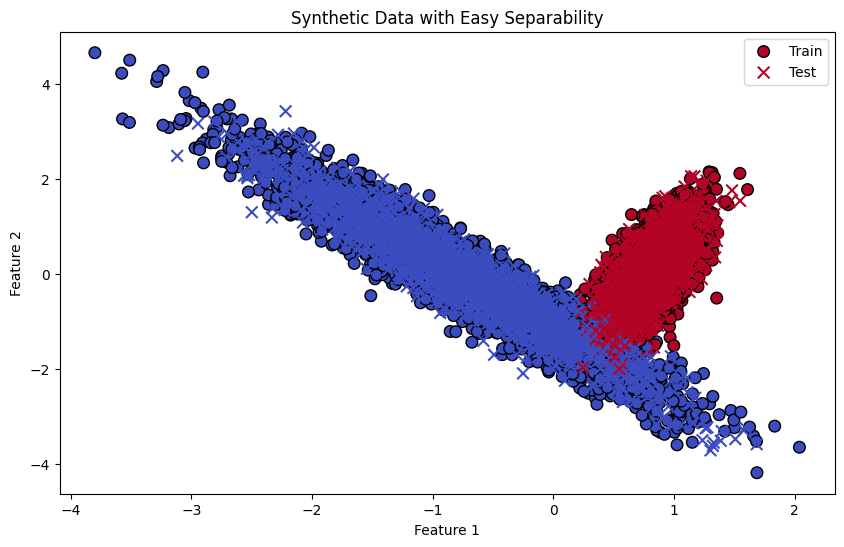

In [4]:
# Plot the generated dataset
plt.figure(figsize=(10, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', marker='o', edgecolor='k', s=70, label='Train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', marker='x', edgecolor='k', s=70, label='Test')
plt.title("Synthetic Data with Easy Separability")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

In [5]:
# Initialize the SVM classifier with polynomial kernel of degree 3
#svm = SVC(kernel='poly', degree=3, C=1.0, random_state=42) # C is the regularization parameter. It controls the trade-off between achieving a low error on the training data and minimizing the model complexity for better generalization to unseen data. A smaller C value creates a softer margin, allowing for more misclassifications, while a larger C value creates a harder margin, aiming to classify all training examples correctly.

svm = SVC(kernel='poly', degree=3, C=1.0, random_state=42)

# Train the classifier
svm.fit(X_train, y_train)

# Make predictions on the test set
y_pred = svm.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.97


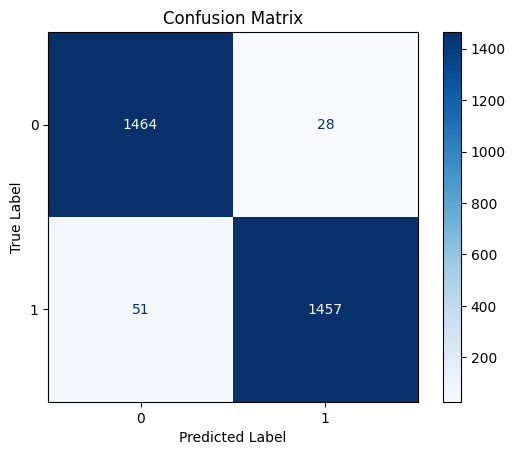

In [6]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [7]:
# Plot the interactive decision boundary using Plotly
import plotly.graph_objects as go

def plot_decision_boundary_interactive(X, y, model, scaler):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), 
                         np.arange(y_min, y_max, 0.05))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Create figure
    fig = go.Figure()
    
    # Add contour plot for decision boundary
    fig.add_trace(go.Contour(
        x=np.arange(x_min, x_max, 0.05),
        y=np.arange(y_min, y_max, 0.05),
        z=Z,
        colorscale='RdBu',
        opacity=0.5,
        showscale=False,
        name='Decision Boundary'
    ))
    
    # Add scatter plot for test points
    fig.add_trace(go.Scatter(
        x=X[:, 0],
        y=X[:, 1],
        mode='markers',
        marker=dict(
            color=y,
            colorscale='RdBu',
            line=dict(width=1, color='black'),
            size=8
        ),
        name='Test Points'
    ))
    
    # Update layout
    fig.update_layout(
        title='Interactive Decision Boundary (SVM)',
        xaxis_title='Feature 1',
        yaxis_title='Feature 2',
        width=900,
        height=600,
        hovermode='closest'
    )
    
    fig.show()

plot_decision_boundary_interactive(X_test, y_test, svm, scaler)

In [9]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Visualize the transformed space of the SVM with support vectors

def polynomial_features_3d(X):
    """Create polynomial features for 3D visualization"""
    x1 = X[:, 0]
    x2 = X[:, 1]
    # We'll use x1^2, x2^2, and x1*x2 for 3D visualization
    return np.column_stack([x1**2, x2**2, x1*x2])

# Transform both training and test data
X_train_transformed = polynomial_features_3d(X_train)
X_test_transformed = polynomial_features_3d(X_test)

# Get support vectors from the SVM model
support_vector_indices = svm.support_
support_vectors = X_train[support_vector_indices]
support_vectors_transformed = X_train_transformed[support_vector_indices]

# Create figure with subplots
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]],
    subplot_titles=("Original Feature Space (2D) - SVM Decision Boundary", 
                    "Transformed Feature Space (3D) - SVM Support Vectors"),
    horizontal_spacing=0.1
)

# Plot 1: Original 2D space with decision boundary
x_min, x_max = X_test[:, 0].min() - 1, X_test[:, 0].max() + 1
y_min, y_max = X_test[:, 1].min() - 1, X_test[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), 
                     np.arange(y_min, y_max, 0.05))
Z = svm.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Add decision boundary contour
fig.add_trace(
    go.Contour(
        x=np.arange(x_min, x_max, 0.05),
        y=np.arange(y_min, y_max, 0.05),
        z=Z,
        colorscale='RdBu',
        opacity=0.4,
        showscale=False,
        name='Decision Boundary',
        contours=dict(showlabels=False)
    ),
    row=1, col=1
)

# Add test data points
fig.add_trace(
    go.Scatter(
        x=X_test[:, 0],
        y=X_test[:, 1],
        mode='markers',
        marker=dict(
            size=6,
            color=y_test,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(x=0.45, len=0.5),
            opacity=0.6,
            line=dict(width=0.5, color='gray')
        ),
        text=y_test,
        hovertemplate="<b>Feature 1:</b> %{x:.2f}<br><b>Feature 2:</b> %{y:.2f}<br><b>Class:</b> %{text}<extra></extra>",
        name="Test Data"
    ),
    row=1, col=1
)

# Add support vectors (highlighted)
fig.add_trace(
    go.Scatter(
        x=support_vectors[:, 0],
        y=support_vectors[:, 1],
        mode='markers',
        marker=dict(
            size=10,
            color='yellow',
            symbol='star',
            line=dict(width=2, color='black')
        ),
        text="Support Vector",
        hovertemplate="<b>Support Vector</b><br>Feature 1: %{x:.2f}<br>Feature 2: %{y:.2f}<extra></extra>",
        name="Support Vectors"
    ),
    row=1, col=1
)

fig.update_xaxes(title_text="Feature 1", row=1, col=1)
fig.update_yaxes(title_text="Feature 2", row=1, col=1)

# Plot 2: Transformed 3D space with support vectors
fig.add_trace(
    go.Scatter3d(
        x=X_test_transformed[:, 0],
        y=X_test_transformed[:, 1],
        z=X_test_transformed[:, 2],
        mode='markers',
        marker=dict(
            size=3,
            color=y_test,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(x=1.02, len=0.5),
            opacity=0.5,
            line=dict(width=0.5, color='gray')
        ),
        text=y_test,
        hovertemplate="<b>x₁²:</b> %{x:.2f}<br><b>x₂²:</b> %{y:.2f}<br><b>x₁·x₂:</b> %{z:.2f}<br><b>Class:</b> %{text}<extra></extra>",
        name="Test Data (Transformed)"
    ),
    row=1, col=2
)

# Add transformed support vectors (highlighted)
fig.add_trace(
    go.Scatter3d(
        x=support_vectors_transformed[:, 0],
        y=support_vectors_transformed[:, 1],
        z=support_vectors_transformed[:, 2],
        mode='markers',
        marker=dict(
            size=8,
            color='yellow',
            symbol='diamond',
            line=dict(width=2, color='black'),
            opacity=0.9
        ),
        text="Support Vector",
        hovertemplate="<b>Support Vector (Transformed)</b><br>x₁²: %{x:.2f}<br>x₂²: %{y:.2f}<br>x₁·x₂: %{z:.2f}<extra></extra>",
        name="Support Vectors (Transformed)"
    ),
    row=1, col=2
)

fig.update_layout(
    scene=dict(
        xaxis_title="$x_1^2$",
        yaxis_title="$x_2^2$",
        zaxis_title="$x_1 \\cdot x_2$",
        camera=dict(
            eye=dict(x=1.5, y=1.5, z=1.3)
        )
    ),
    title_text=f"SVM Polynomial Kernel Transformation - {len(support_vector_indices)} Support Vectors",
    height=600,
    width=1400,
    hovermode='closest'
)

fig.show()

# Print support vector statistics
print(f"\nSVM Model Statistics:")
print(f"Total training samples: {len(X_train)}")
print(f"Number of support vectors: {len(support_vector_indices)}")
print(f"Support vector ratio: {len(support_vector_indices) / len(X_train) * 100:.2f}%")


SVM Model Statistics:
Total training samples: 7000
Number of support vectors: 1029
Support vector ratio: 14.70%
